## Configuración

In [67]:
import io
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedGroupKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

SEMILLA = 30
np.random.seed(SEMILLA)

# Día de cursada en el que se genera la alerta (día 0 = inicio del módulo).
CORTE = 30

# Períodos: se entrena con el pasado y se evalúa con el período más reciente.
PERIODOS_TRAIN = ["2013B", "2013J", "2014B"]
PERIODO_TEST = "2014J"

DATA_DIR = Path("data")
FIG_DIR = Path("figuras")
for carpeta in (DATA_DIR, FIG_DIR):
    carpeta.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
COLORES = {"Regla heurística": "#9e9e9e", "Regresión logística": "#4c72b0",
           "Random Forest": "#55a868", "XGBoost": "#dd8452"}


def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")

## Carga de datos

Los valores faltantes vienen codificados como `?` en los CSV originales.

In [68]:
URL_OULAD = "https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip"

if not (DATA_DIR / "studentVle.csv").exists():
    print("Descargando OULAD desde UCI (~45 MB)...")
    with urllib.request.urlopen(URL_OULAD) as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(DATA_DIR)

NA = ["?"]
courses = pd.read_csv(DATA_DIR / "courses.csv")
info = pd.read_csv(DATA_DIR / "studentInfo.csv", na_values=NA)
reg = pd.read_csv(DATA_DIR / "studentRegistration.csv", na_values=NA)
assessments = pd.read_csv(DATA_DIR / "assessments.csv", na_values=NA)
st_asm = pd.read_csv(DATA_DIR / "studentAssessment.csv", na_values=NA)
vle = pd.read_csv(DATA_DIR / "vle.csv", na_values=NA)
st_vle = pd.read_csv(
    DATA_DIR / "studentVle.csv",
    dtype={"code_module": "category", "code_presentation": "category",
           "id_student": "int32", "id_site": "int32", "date": "int16", "sum_click": "int32"},
)

PRES = ["code_module", "code_presentation"]
KEYS = PRES + ["id_student"]



In [69]:
tablas = {"courses": courses, "studentInfo": info, "studentRegistration": reg,
          "assessments": assessments, "studentAssessment": st_asm, "vle": vle, "studentVle": st_vle}
resumen = pd.DataFrame({
    "filas": {k: len(v) for k, v in tablas.items()},
    "columnas": {k: v.shape[1] for k, v in tablas.items()},
    "celdas nulas": {k: int(v.isna().sum().sum()) for k, v in tablas.items()},
})
resumen

,filas,columnas,celdas nulas
courses,22,3,0
studentInfo,32593,12,1111
studentRegistration,32593,5,22566
assessments,206,6,11
studentAssessment,173912,5,173
vle,6364,6,10486
studentVle,10655280,6,0


## Comprensión de los datos

### Calidad de datos

In [70]:
inscr = info.merge(reg, on=KEYS, how="left")

calidad = pd.DataFrame([
    ("Inscripciones duplicadas (módulo, cursada, alumno)", info.duplicated(KEYS).sum(), "Ninguna: no requiere acción"),
    ("imd_band nulo (índice de privación del barrio)", info.imd_band.isna().sum(), "Imputar mediana + indicador de faltante"),
    ("imd_band con formato inconsistente ('10-20' sin %)", (info.imd_band == "10-20").sum(), "Normalizar a decil 0–9"),
    ("date_registration nulo", reg.date_registration.isna().sum(), "Imputar mediana + indicador"),
    ("Abandono (Withdrawn) sin fecha de baja", ((inscr.final_result == "Withdrawn") & inscr.date_unregistration.isna()).sum(),
     "Excluir: no se puede saber si ya se habían ido al día del corte"),
    ("Con fecha de baja pero resultado ≠ Withdrawn", ((inscr.final_result != "Withdrawn") & inscr.date_unregistration.notna()).sum(),
     "Se respeta final_result (son 'Fail')"),
    ("Inscriptos después del día del corte", (inscr.date_registration > CORTE).sum(), "Excluir: no estaban cursando aún"),
    ("Evaluaciones sin fecha (todas son exámenes finales)", assessments.date.isna().sum(), "No afectan: ocurren después del corte"),
    ("Entregas sin nota", st_asm.score.isna().sum(), "Cuentan como entrega; la nota queda nula"),
    ("Alumnos que recursan (aparecen en >1 cursada)", info.id_student.duplicated().sum(),
     "Validación cruzada agrupada por alumno"),
], columns=["Problema", "Casos", "Decisión"])
calidad

,Problema,Casos,Decisión
0,"Inscripciones duplicadas (módulo, cursada, alu...",0,Ninguna: no requiere acción
1,imd_band nulo (índice de privación del barrio),1111,Imputar mediana + indicador de faltante
2,imd_band con formato inconsistente ('10-20' si...,3516,Normalizar a decil 0–9
3,date_registration nulo,45,Imputar mediana + indicador
4,Abandono (Withdrawn) sin fecha de baja,93,Excluir: no se puede saber si ya se habían ido...
5,Con fecha de baja pero resultado ≠ Withdrawn,9,Se respeta final_result (son 'Fail')
6,Inscriptos después del día del corte,16,Excluir: no estaban cursando aún
7,Evaluaciones sin fecha (todas son exámenes fin...,11,No afectan: ocurren después del corte
8,Entregas sin nota,173,Cuentan como entrega; la nota queda nula
9,Alumnos que recursan (aparecen en >1 cursada),3808,Validación cruzada agrupada por alumno


### Variable objetivo

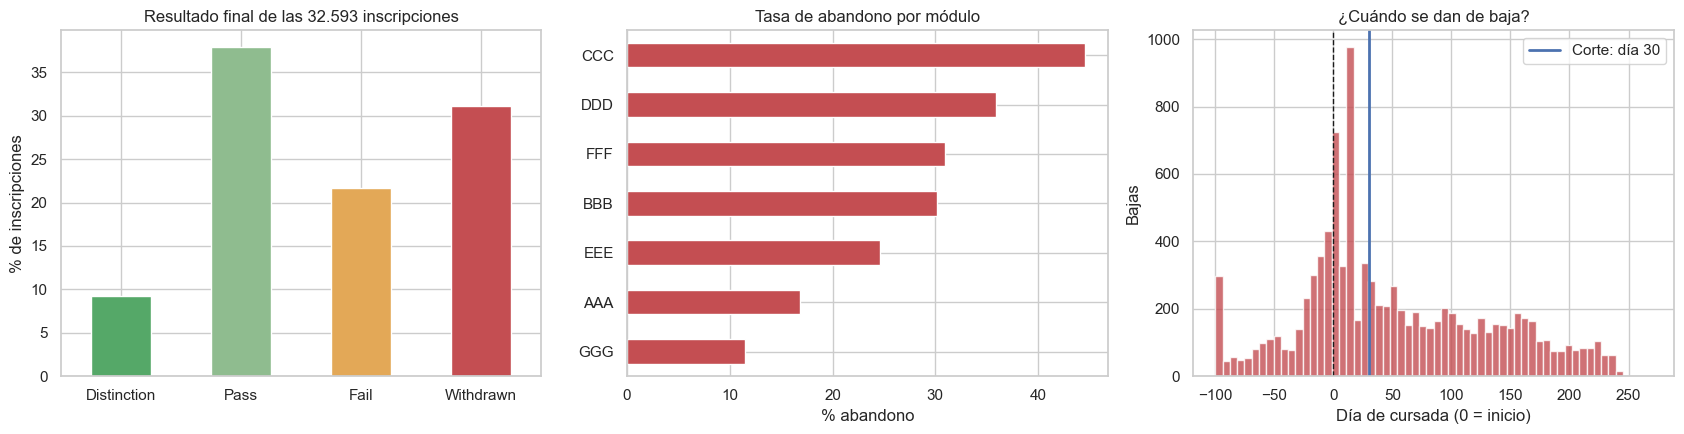

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

orden = ["Distinction", "Pass", "Fail", "Withdrawn"]
info.final_result.value_counts(normalize=True).reindex(orden).mul(100).plot.bar(
    ax=axes[0], color=["#55a868", "#8fbc8f", "#e3a857", "#c44e52"])
axes[0].set(title="Resultado final de las 32.593 inscripciones", ylabel="% de inscripciones", xlabel="")
axes[0].tick_params(axis="x", rotation=0)

(info.assign(abandono=info.final_result.eq("Withdrawn"))
     .groupby("code_module").abandono.mean().mul(100).sort_values()
     .plot.barh(ax=axes[1], color="#c44e52"))
axes[1].set(title="Tasa de abandono por módulo", xlabel="% abandono", ylabel="")

bajas = inscr.loc[inscr.final_result.eq("Withdrawn"), "date_unregistration"].dropna()
axes[2].hist(bajas.clip(-100, 270), bins=60, color="#c44e52", alpha=.8)
axes[2].axvline(0, color="k", ls="--", lw=1)
axes[2].axvline(CORTE, color="#4c72b0", lw=2, label=f"Corte: día {CORTE}")
axes[2].set(title="¿Cuándo se dan de baja?", xlabel="Día de cursada (0 = inicio)", ylabel="Bajas")
axes[2].legend()
fig.tight_layout()
guardar(fig, "01_objetivo")

### Perfil del estudiante y deserción

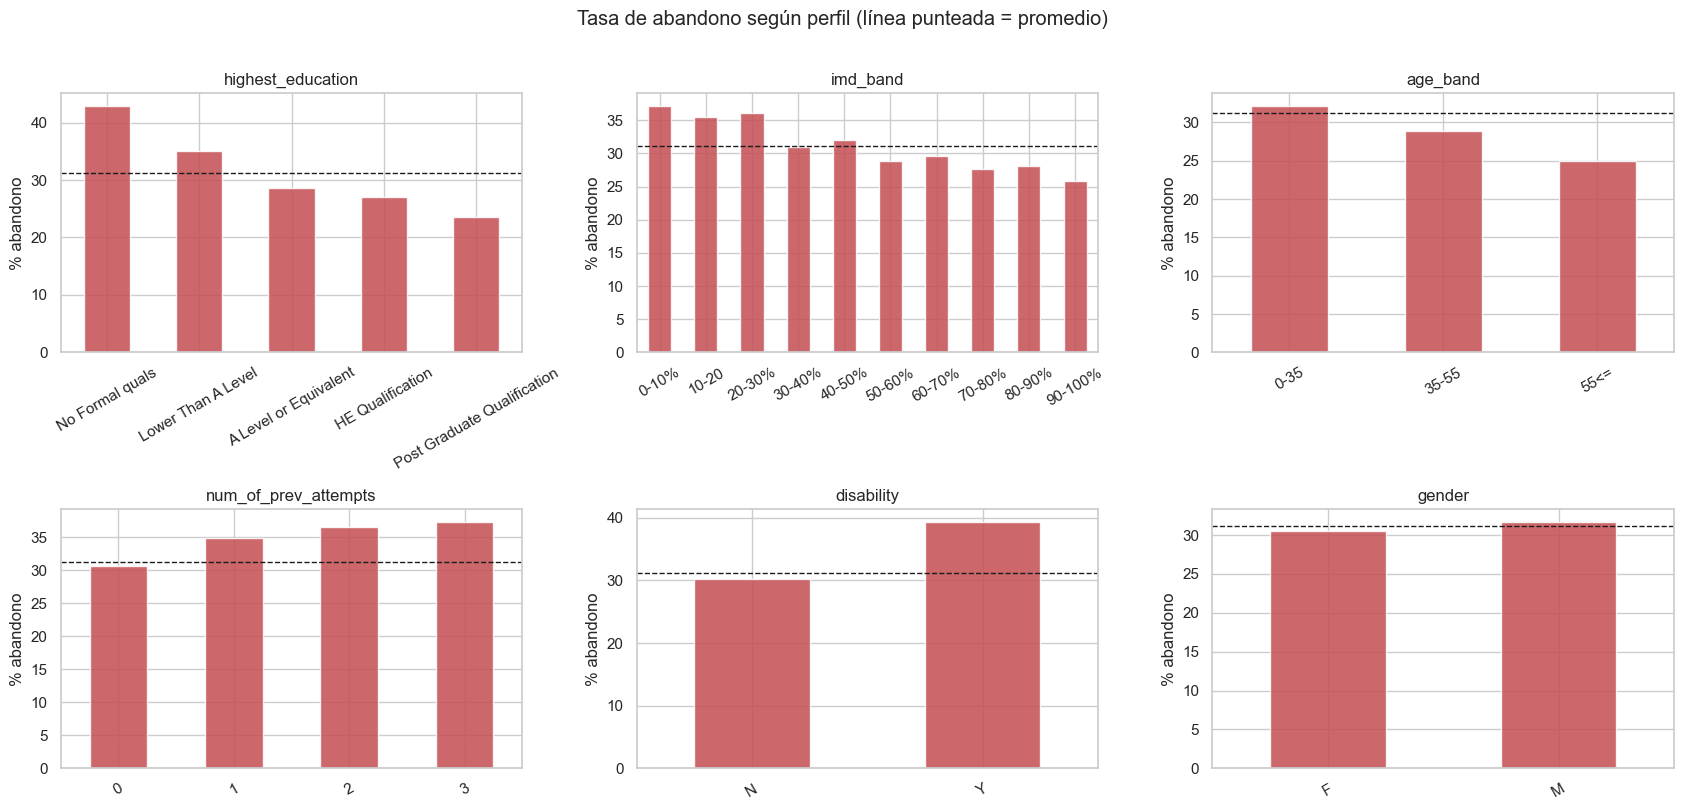

In [72]:
perfil = info.assign(abandono=info.final_result.eq("Withdrawn"))
variables = {"highest_education": ["No Formal quals", "Lower Than A Level", "A Level or Equivalent",
                                   "HE Qualification", "Post Graduate Qualification"],
             "imd_band": ["0-10%", "10-20", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"],
             "age_band": ["0-35", "35-55", "55<="],
             "num_of_prev_attempts": [0, 1, 2, 3],
             "disability": ["N", "Y"],
             "gender": ["F", "M"]}
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (var, cats) in zip(axes.flat, variables.items()):
    tasa = perfil.groupby(var).abandono.mean().reindex(cats).mul(100)
    tasa.plot.bar(ax=ax, color="#c44e52", alpha=.85)
    ax.axhline(perfil.abandono.mean() * 100, color="k", ls="--", lw=1)
    ax.set(title=var, xlabel="", ylabel="% abandono")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Tasa de abandono según perfil (línea punteada = promedio)", y=1.01)
fig.tight_layout()
guardar(fig, "02_perfil")

### Actividad en el campus virtual (primeros 30 días)

La distribución de clics es muy asimétrica, con mucho outlier, así que se le aplica una tranformación log1p para atenuar

,count,mean,std,min,25%,50%,75%,max
Resultado,,,,,,,,
Abandona después,5037.0,301.0,368.0,0.0,79.0,193.0,397.0,6388.0
Completa,22429.0,391.0,465.0,0.0,99.0,249.0,518.0,8057.0


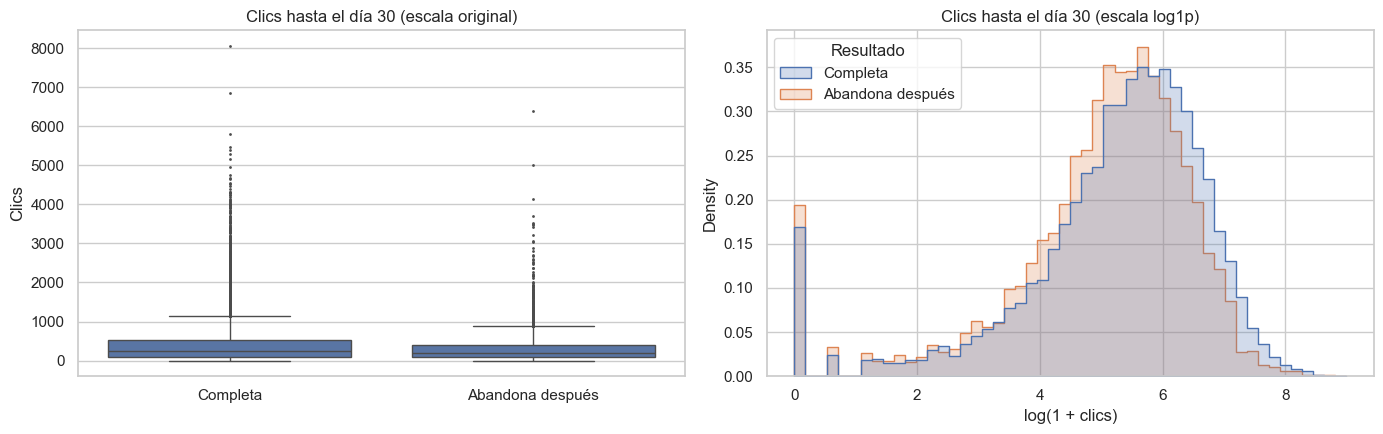

In [73]:
act = (st_vle[st_vle.date <= CORTE].groupby(KEYS, observed=True).sum_click.sum()
       .rename("clicks").reset_index().astype({"code_module": str, "code_presentation": str}))
act = inscr.merge(act, on=KEYS, how="left").fillna({"clicks": 0})
act = act[act.date_unregistration.isna() | (act.date_unregistration > CORTE)]
act["Resultado"] = np.where(act.final_result.eq("Withdrawn"), "Abandona después", "Completa")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=act, x="Resultado", y="clicks", ax=axes[0], showfliers=True, fliersize=1)
axes[0].set(title=f"Clics hasta el día {CORTE} (escala original)", ylabel="Clics", xlabel="")
sns.histplot(data=act, x=np.log1p(act.clicks), hue="Resultado", stat="density", common_norm=False,
             bins=50, ax=axes[1], element="step")
axes[1].set(title="Clics hasta el día 30 (escala log1p)", xlabel="log(1 + clics)")
fig.tight_layout()
guardar(fig, "03_clicks")
act.groupby("Resultado").clicks.describe().round(0)

Quienes abandonan después del día 30 muestran **alrededor de un 20–25% menos de actividad** en el primer mes (mediana de 193 contra 249 clics), con distribuciones muy superpuestas. La señal existe pero es moderada: anticipa que la predicción temprana va a ser difícil.

## Preparación de datos

`construir_dataset(corte)` arma una fila por inscripción **usando solo información disponible hasta el día `corte`**:

1. **Población:** inscriptos que siguen activos al día del corte. Se excluyen quienes ya se dieron de baja, quienes todavía no se habían inscripto y los abandonos sin fecha de baja.
2. **Objetivo:** `abandono = 1` si el resultado final es *Withdrawn* (necesariamente con baja posterior al corte).
3. **Variables:** perfil, contexto del módulo, actividad en el campus virtual (volumen, regularidad, recencia, tendencia, tipo de recurso) y evaluaciones (entregas, atrasos, notas).


In [74]:
ORDEN_EDUCACION = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2,
                   "HE Qualification": 3, "Post Graduate Qualification": 4}
ORDEN_EDAD = {"0-35": 0, "35-55": 1, "55<=": 2}
TIPOS_PRINCIPALES = ["homepage", "oucontent", "resource", "subpage", "url", "forumng", "quiz"]

st_vle_tipo = st_vle.merge(vle[["id_site", "activity_type"]], on="id_site", how="left")
st_vle_tipo["tipo"] = (st_vle_tipo.activity_type.where(st_vle_tipo.activity_type.isin(TIPOS_PRINCIPALES), "otros")
                       .astype("category"))
st_vle_tipo = st_vle_tipo.drop(columns="activity_type").astype({"code_module": str, "code_presentation": str})

st_asm_det = st_asm.merge(assessments, on="id_assessment", how="left")


def construir_dataset(corte: int) -> pd.DataFrame:
    df = info.merge(reg, on=KEYS, how="left").merge(courses, on=PRES, how="left")

    # --- Población a riesgo en el día del corte -------------------------------------------
    sin_fecha_baja = df.final_result.eq("Withdrawn") & df.date_unregistration.isna()
    ya_dado_de_baja = df.date_unregistration.notna() & (df.date_unregistration <= corte)
    aun_no_inscripto = df.date_registration > corte
    df = df[~(sin_fecha_baja | ya_dado_de_baja | aun_no_inscripto)].copy()
    df["abandono"] = df.final_result.eq("Withdrawn").astype(int)

    # --- Perfil y contexto ----------------------------------------------------------------
    df["educacion_nivel"] = df.highest_education.map(ORDEN_EDUCACION)
    df["edad_nivel"] = df.age_band.map(ORDEN_EDAD)
    df["imd_decil"] = df.imd_band.str.extract(r"^(\d+)")[0].astype(float) // 10  # 0 = 0-10% … 9 = 90-100%
    df["semestre"] = df.code_presentation.str[-1]  # B = inicia en febrero, J = en octubre
    df["dias_inscripcion_anticipada"] = -df.date_registration
    df["duracion_modulo"] = df.module_presentation_length

    # --- Campus virtual (VLE) -------------------------------------------------------------
    v = st_vle_tipo[st_vle_tipo.date <= corte].merge(df[KEYS], on=KEYS)
    g = v.groupby(KEYS)
    vf = pd.DataFrame({
        "clicks_total": g.sum_click.sum(),
        "dias_activos": g.date.nunique(),
        "recursos_distintos": g.id_site.nunique(),
        "ultimo_dia_activo": g.date.max(),
    })
    vf["clicks_pre_inicio"] = v[v.date < 0].groupby(KEYS).sum_click.sum()
    vf["clicks_ult_14d"] = v[v.date > corte - 14].groupby(KEYS).sum_click.sum()
    vf["clicks_14d_previos"] = v[(v.date > corte - 28) & (v.date <= corte - 14)].groupby(KEYS).sum_click.sum()
    vf["dias_activos_ult_14d"] = v[v.date > corte - 14].groupby(KEYS).date.nunique()
    por_tipo = v.groupby(KEYS + ["tipo"], observed=True).sum_click.sum().unstack(fill_value=0)
    por_tipo.columns = [f"clicks_{c}" for c in por_tipo.columns]
    vf = vf.join(por_tipo)
    df = df.merge(vf, left_on=KEYS, right_index=True, how="left")

    conteos_vle = [c for c in vf.columns if c != "ultimo_dia_activo"]
    df[conteos_vle] = df[conteos_vle].fillna(0)
    df["sin_actividad_vle"] = df.ultimo_dia_activo.isna().astype(int)
    inicio_posible = df.date_registration.fillna(df.date_registration.median()).clip(upper=corte)
    df["dias_sin_actividad"] = (corte - df.ultimo_dia_activo).fillna(corte - inicio_posible)
    df["tendencia_clicks"] = (df.clicks_ult_14d + 1) / (df.clicks_14d_previos + 1)
    # Actividad relativa a la mediana de su propia cursada (los módulos difieren mucho entre sí)
    df["clicks_relativos"] = df.clicks_total / df.groupby(PRES).clicks_total.transform("median").clip(lower=1)

    # --- Evaluaciones ---------------------------------------------------------------------
    vencidas = assessments[assessments.date <= corte].groupby(PRES).size().rename("evaluaciones_vencidas")
    df = df.merge(vencidas, left_on=PRES, right_index=True, how="left").fillna({"evaluaciones_vencidas": 0})

    s = st_asm_det[st_asm_det.date_submitted <= corte].merge(df[KEYS], on=KEYS)
    s["dias_atraso"] = s.date_submitted - s.date
    s["tardia"] = (s.dias_atraso > 0).astype(int)
    s["peso_x_nota"] = s.score * s.weight
    g = s.groupby(KEYS)
    ef = pd.DataFrame({
        "entregas": g.size(),
        "entregas_tardias": g.tardia.sum(),
        "entregas_convalidadas": g.is_banked.sum(),
        "nota_media": g.score.mean(),
        "nota_minima": g.score.min(),
        "atraso_medio": g.dias_atraso.mean(),
        "nota_ponderada": g.peso_x_nota.sum() / g.weight.sum().replace(0, np.nan),
    })
    ef["vencidas_entregadas"] = s[s.date <= corte].groupby(KEYS).size()
    df = df.merge(ef, left_on=KEYS, right_index=True, how="left")
    df[["entregas", "entregas_tardias", "entregas_convalidadas", "vencidas_entregadas"]] = (
        df[["entregas", "entregas_tardias", "entregas_convalidadas", "vencidas_entregadas"]].fillna(0))
    df["vencidas_no_entregadas"] = (df.evaluaciones_vencidas - df.vencidas_entregadas).clip(lower=0)
    df["tasa_entrega"] = df.vencidas_entregadas / df.evaluaciones_vencidas.replace(0, np.nan)

    return df.reset_index(drop=True)


df = construir_dataset(CORTE)
print(f"Día de corte {CORTE}: {len(df):,} inscripciones activas · tasa de abandono posterior: {df.abandono.mean():.1%}")
df.groupby("code_presentation").abandono.agg(["size", "mean"]).rename(columns={"size": "inscripciones", "mean": "tasa_abandono"})

Día de corte 30: 27,357 inscripciones activas · tasa de abandono posterior: 18.1%


,inscripciones,tasa_abandono
code_presentation,,
2013B,4106,0.188261
2013J,7650,0.154902
2014B,6490,0.200770
2014J,9111,0.184392


### Diccionario de variables

In [75]:
CONTEOS = [  # no negativos y muy asimétricos → log1p
    "clicks_total", "clicks_pre_inicio", "clicks_ult_14d", "clicks_14d_previos", "dias_activos",
    "dias_activos_ult_14d", "recursos_distintos", "clicks_relativos", "tendencia_clicks",
    *[f"clicks_{t}" for t in TIPOS_PRINCIPALES + ["otros"]],
    "entregas", "entregas_tardias", "entregas_convalidadas", "vencidas_no_entregadas", "studied_credits",
]
NUMERICAS = [
    "dias_sin_actividad", "sin_actividad_vle", "evaluaciones_vencidas", "tasa_entrega", "nota_media",
    "nota_minima", "nota_ponderada", "atraso_medio", "num_of_prev_attempts", "dias_inscripcion_anticipada",
    "duracion_modulo", "educacion_nivel", "edad_nivel", "imd_decil",
]
CATEGORICAS = ["code_module", "semestre", "gender", "region", "disability"]
SENSIBLES = ["gender", "disability", "edad_nivel", "imd_decil", "region"]
FEATURES = CONTEOS + NUMERICAS + CATEGORICAS

descripciones = {
    "clicks_total": "Clics totales en el campus virtual hasta el corte",
    "clicks_relativos": "Clics totales / mediana de su cursada",
    "clicks_ult_14d": "Clics en los últimos 14 días previos al corte",
    "tendencia_clicks": "Clics últimos 14 días / 14 días anteriores (>1 = en aumento)",
    "dias_activos": "Días distintos con actividad",
    "dias_sin_actividad": "Días desde la última actividad (recencia)",
    "clicks_pre_inicio": "Clics antes del día 0 (preparación previa)",
    "vencidas_no_entregadas": "Evaluaciones con fecha vencida que no entregó",
    "tasa_entrega": "Entregadas a tiempo / evaluaciones vencidas",
    "nota_media": "Nota promedio de lo entregado (0–100)",
    "num_of_prev_attempts": "Veces que ya cursó el módulo",
    "studied_credits": "Créditos que cursa en simultáneo (carga)",
    "dias_inscripcion_anticipada": "Días entre la inscripción y el inicio",
    "educacion_nivel": "Nivel educativo previo (0 = sin estudios formales … 4 = posgrado)",
    "imd_decil": "Decil de privación del barrio (0 = más desfavorecido)",
}
diccionario = pd.DataFrame({
    "descripción": pd.Series(descripciones),
    "tipo": ["Comportamiento" if c not in SENSIBLES + ["num_of_prev_attempts", "studied_credits", "educacion_nivel",
                                                      "dias_inscripcion_anticipada"] else "Perfil" for c in descripciones],
    "nulos_%": df[list(descripciones)].isna().mean().mul(100).round(1),
    "mediana (abandona)": df[df.abandono == 1][list(descripciones)].median().round(2),
    "mediana (no abandona)": df[df.abandono == 0][list(descripciones)].median().round(2),
})

diccionario

,descripción,tipo,nulos_%,mediana (abandona),mediana (no abandona)
clicks_total,Clics totales en el campus virtual hasta el corte,Comportamiento,0.0,197.00,249.00
clicks_relativos,Clics totales / mediana de su cursada,Comportamiento,0.0,0.77,1.06
clicks_ult_14d,Clics en los últimos 14 días previos al corte,Comportamiento,0.0,64.00,79.00
tendencia_clicks,Clics últimos 14 días / 14 días anteriores (>1...,Comportamiento,0.0,1.00,0.96
dias_activos,Días distintos con actividad,Comportamiento,0.0,12.00,14.00
dias_sin_actividad,Días desde la última actividad (recencia),Comportamiento,0.0,1.00,1.00
clicks_pre_inicio,Clics antes del día 0 (preparación previa),Comportamiento,0.0,20.00,29.00
vencidas_no_entregadas,Evaluaciones con fecha vencida que no entregó,Comportamiento,0.0,0.00,0.00
tasa_entrega,Entregadas a tiempo / evaluaciones vencidas,Comportamiento,18.2,1.00,1.00
nota_media,Nota promedio de lo entregado (0–100),Comportamiento,23.9,70.00,79.00


### Partición fuera de tiempo

Para imitar el uso real, el modelo se entrena con los períodos 2013B, 2013J y 2014B y se evalúa con el período **2014J**, que funciona como "el próximo semestre". Dentro del conjunto de entrenamiento, la validación cruzada (5 *folds*) se **agrupa por estudiante**, para que un mismo alumno que recursa no quede a la vez en entrenamiento y en validación.

In [76]:
train = df[df.code_presentation.isin(PERIODOS_TRAIN)].reset_index(drop=True)
test = df[df.code_presentation.eq(PERIODO_TEST)].reset_index(drop=True)
X_train, y_train, grupos = train[FEATURES], train.abandono, train.id_student
X_test, y_test = test[FEATURES], test.abandono
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pd.DataFrame({"inscripciones": [len(train), len(test)],
              "abandonos": [y_train.sum(), y_test.sum()],
              "tasa_abandono": [y_train.mean().round(3), y_test.mean().round(3)]},
             index=["Entrenamiento (2013B-2014B)", "Test (2014J)"])

,inscripciones,abandonos,tasa_abandono
Entrenamiento (2013B-2014B),18246,3261,0.179
Test (2014J),9111,1680,0.184


In [77]:
def preprocesador(conteos, numericas, categoricas):
    return ColumnTransformer([
        ("conteos", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("esc", StandardScaler())]), conteos),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("esc", StandardScaler())]), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
    ], verbose_feature_names_out=False)

## Línea base

- **Azar:** contactar estudiantes al azar. Su PR-AUC es igual a la tasa de abandono.
- **Regla heurística** (benchmark de negocio, lo que haría un tutor sin modelo): marcar en riesgo a quien **no tuvo actividad en los últimos 14 días** *o* **tiene alguna evaluación vencida sin entregar**. El puntaje (0, 1 o 2) cuenta cuántas de las dos condiciones cumple.

In [78]:
def regla_heuristica(d):
    return (d.dias_activos_ult_14d.eq(0).astype(int) + d.vencidas_no_entregadas.gt(0).astype(int)).to_numpy()


def metricas(y, score, umbral=None, capacidad=0.30):
    """Métricas de ranking + desempeño con un umbral y con capacidad de contacto fija (top-k)."""
    res = {"ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score)}
    k = int(np.ceil(capacidad * len(y)))
    top = np.zeros(len(y), dtype=bool)
    top[np.argsort(-score, kind="stable")[:k]] = True
    res[f"Recall@{capacidad:.0%}"] = recall_score(y, top)
    res[f"Precisión@{capacidad:.0%}"] = precision_score(y, top)
    if umbral is not None:
        pred = score >= umbral
        res.update({"Umbral": umbral, "Precisión": precision_score(y, pred), "Recall": recall_score(y, pred),
                    "F1": f1_score(y, pred), "% alertados": pred.mean()})
    return res


base = pd.DataFrame({
    "Azar": {"ROC-AUC": 0.5, "PR-AUC": y_test.mean()},
    "Regla heurística": metricas(y_test, regla_heuristica(test), umbral=1),
}).T
base

,ROC-AUC,PR-AUC,Recall@30%,Precisión@30%,Umbral,Precisión,Recall,F1,% alertados
Azar,0.500000,0.184392,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Regla heurística,0.542838,0.208791,0.31131,0.191295,1.0,0.292844,0.185119,0.226842,0.116562


## Modelado

Se comparan tres algoritmos de complejidad creciente, todos dentro del mismo *pipeline* de preprocesamiento:

| Modelo | Por qué |
|---|---|
| **Regresión logística** | Interpretable, con coeficientes explicables; es la referencia lineal. |
| **Random Forest** | Captura no linealidades e interacciones, y es robusto a outliers. |
| **XGBoost** | *Gradient boosting*, el estado del arte en datos tabulares. |

El desbalance de clases (~20% positivos) se maneja con pesos de clase. Los hiperparámetros se buscan con *RandomizedSearchCV* maximizando la PR-AUC en la validación cruzada agrupada.

In [ ]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
prep = preprocesador(CONTEOS, NUMERICAS, CATEGORICAS)

candidatos = {
    "Regresión logística": (
        LogisticRegression(max_iter=3000, class_weight="balanced"),
        {"clf__C": loguniform(1e-3, 10)}, 12),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEMILLA),
        {"clf__max_depth": [6, 10, 14, None], "clf__min_samples_leaf": [1, 5, 10, 20, 40],
         "clf__max_features": ["sqrt", 0.3, 0.5]}, 12),
    "XGBoost": (
        XGBClassifier(tree_method="hist", eval_metric="aucpr", scale_pos_weight=pos_weight, n_jobs=-1,
                      random_state=SEMILLA),
        {"clf__n_estimators": randint(150, 600), "clf__max_depth": randint(2, 7),
         "clf__learning_rate": loguniform(0.02, 0.2), "clf__subsample": uniform(0.6, 0.4),
         "clf__colsample_bytree": uniform(0.4, 0.6), "clf__min_child_weight": randint(1, 20),
         "clf__reg_lambda": loguniform(0.5, 20)}, 25),
}

mejores, resultados_cv, oof = {}, {}, {}
for nombre, (clf, grilla, n_iter) in candidatos.items():
    busqueda = RandomizedSearchCV(
        Pipeline([("prep", prep), ("clf", clf)]), grilla, n_iter=n_iter, scoring="average_precision",
        cv=cv, random_state=SEMILLA, n_jobs=1 if nombre != "Regresión logística" else -1)
    busqueda.fit(X_train, y_train, groups=grupos)
    mejores[nombre] = busqueda.best_estimator_
    cvres = cross_validate(busqueda.best_estimator_, X_train, y_train, groups=grupos, cv=cv,
                           scoring=["roc_auc", "average_precision"])
    resultados_cv[nombre] = {
        "PR-AUC CV (media)": cvres["test_average_precision"].mean(), "PR-AUC CV (desvío)": cvres["test_average_precision"].std(),
        "ROC-AUC CV (media)": cvres["test_roc_auc"].mean(), "ROC-AUC CV (desvío)": cvres["test_roc_auc"].std(),
    }
    # Predicciones fuera de muestra (out-of-fold): se usan para elegir el umbral sin tocar el test
    oof[nombre] = cross_val_predict(busqueda.best_estimator_, X_train, y_train, groups=grupos, cv=cv,
                                    method="predict_proba")[:, 1]
    print(f"{nombre:20s} PR-AUC CV = {resultados_cv[nombre]['PR-AUC CV (media)']:.3f} "
          f"± {resultados_cv[nombre]['PR-AUC CV (desvío)']:.3f} · mejores hiperparámetros: "
          f"{ {k.replace('clf__', ''): (round(v, 3) if isinstance(v, float) else v) for k, v in busqueda.best_params_.items()} }")

pd.DataFrame(resultados_cv).T.round(3)

Regresión logística  PR-AUC CV = 0.376 ± 0.026 · mejores hiperparámetros: {'C': np.float64(0.042)}


### Elección del umbral

El umbral de cada modelo se elige con las predicciones *out-of-fold* del entrenamiento, maximizando el F1. **El test no se usa para ninguna decisión.**

In [ ]:
umbrales = {}
for nombre, p in oof.items():
    prec, rec, thr = precision_recall_curve(y_train, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    umbrales[nombre] = thr[np.argmax(f1[:-1])]
pd.Series(umbrales, name="umbral F1-óptimo (OOF)").round(3)

## Evaluación en el estudiantado de test (período 2014J)

In [ ]:
proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in mejores.items()}
comparacion = pd.DataFrame(
    {"Regla heurística": metricas(y_test, regla_heuristica(test), umbral=1),
     **{n: metricas(y_test, p, umbral=umbrales[n]) for n, p in proba_test.items()}}).T
comparacion = pd.DataFrame(resultados_cv).T[["PR-AUC CV (media)", "PR-AUC CV (desvío)"]].join(comparacion, how="right")
for n, p in proba_test.items():
    comparacion.loc[n, "Brier"] = brier_score_loss(y_test, p)

comparacion.round(3)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
reglas = {"Regla heurística": regla_heuristica(test), **proba_test}
for nombre, p in reglas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    estilo = dict(color=COLORES[nombre], lw=2.2 if nombre == "XGBoost" else 1.5,
                  ls="--" if nombre == "Regla heurística" else "-",
                  marker="o" if nombre == "Regla heurística" else None)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, p):.3f})", **estilo)
    axes[1].plot(rec, prec, label=f"{nombre} (AP={average_precision_score(y_test, p):.3f})", **estilo)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set(title="Curva ROC — período 2014J", xlabel="Tasa de falsos positivos", ylabel="Recall (sensibilidad)")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1, label=f"Azar ({y_test.mean():.3f})")
axes[1].set(title="Curva Precisión–Recall — período 2014J", xlabel="Recall", ylabel="Precisión")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
fig.tight_layout()
guardar(fig, "04_curvas_roc_pr")

**Lectura:** los tres algoritmos rinden de forma muy parecida: las diferencias en PR-AUC de validación cruzada son del orden de su desvío entre *folds*. Lo que mueve la aguja son las variables, no el algoritmo. Todos superan con claridad a la regla heurística, que apenas mejora al azar: al día 30 casi todos los futuros desertores siguen activos y entregando, así que hacen falta señales más finas (actividad *relativa* a su cursada, tendencia, notas) que una regla simple no captura. La regresión logística queda como alternativa válida si se prioriza la explicabilidad.

### Modelo final e intervalos de confianza

Se elige el modelo con **mayor PR-AUC en validación cruzada**, un criterio decidido antes de mirar el test. Para cuantificar la incertidumbre de las métricas en test se usa *bootstrap* (1.000 remuestreos).

In [ ]:
FINAL = max(resultados_cv, key=lambda n: resultados_cv[n]["PR-AUC CV (media)"])
modelo_final, umbral_final, p_final = mejores[FINAL], umbrales[FINAL], proba_test[FINAL]
print(f"Modelo final: {FINAL} · umbral = {umbral_final:.3f}")

rng = np.random.default_rng(SEMILLA)
boot = []
yt = y_test.to_numpy()
p_regla = regla_heuristica(test)
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    boot.append({"ROC-AUC": roc_auc_score(yt[i], p_final[i]), "PR-AUC": average_precision_score(yt[i], p_final[i]),
                 "Recall": recall_score(yt[i], p_final[i] >= umbral_final),
                 "Precisión": precision_score(yt[i], p_final[i] >= umbral_final),
                 "Mejora PR-AUC vs regla": average_precision_score(yt[i], p_final[i]) - average_precision_score(yt[i], p_regla[i])})
boot = pd.DataFrame(boot)
ic = boot.quantile([0.025, 0.5, 0.975]).T.rename(columns={0.025: "IC 2,5%", 0.5: "mediana", 0.975: "IC 97,5%"})

ic.round(3)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
cm = confusion_matrix(y_test, p_final >= umbral_final)
sns.heatmap(cm, annot=np.array([[f"{v:,}\n({v / cm.sum():.0%})" for v in fila] for fila in cm]), fmt="",
            cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["No alertado", "Alertado"], yticklabels=["Completa", "Abandona"])
axes[0].set(title=f"Matriz de confusión — {FINAL} (umbral {umbral_final:.2f})", xlabel="Predicción", ylabel="Realidad")

frac_pos, media_pred = calibration_curve(y_test, p_final, n_bins=10, strategy="quantile")
axes[1].plot(media_pred, frac_pos, "o-", color=COLORES[FINAL], label=FINAL)
axes[1].plot([0, 1], [0, 1], "k:", label="Calibración perfecta")
axes[1].set(title="Calibración", xlabel="Probabilidad predicha", ylabel="Tasa real de abandono")
axes[1].legend()
fig.tight_layout()
guardar(fig, "05_confusion_calibracion")

Por los pesos de clase, el modelo **sobreestima la probabilidad absoluta** de abandono, aunque ordena bien a los estudiantes por riesgo. Para el uso propuesto (priorizar a quién contactar) alcanza con un buen ordenamiento. Si se quisiera comunicar probabilidades ("este alumno tiene 40% de riesgo"), habría que recalibrar el modelo, por ejemplo con `CalibratedClassifierCV` isotónico.

## Interpretabilidad: ¿qué explica el riesgo?

Se usan tres técnicas clásicas, todas calculadas sobre el estudiantado de test:

1. **Importancia por permutación:** se mezcla al azar una variable (o una familia de variables) y se mide cuánto cae la PR-AUC. Cuanto más cae, más depende el modelo de esa información.
2. **Dependencia parcial:** muestra cómo cambia el riesgo predicho, en promedio, al variar una variable y dejar el resto igual.
3. **Perfil por grupo de riesgo:** compara a los estudiantes que el modelo marca como de mayor riesgo con el resto, usando los datos reales.

### Importancia por permutación

In [ ]:
perm = permutation_importance(modelo_final, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=SEMILLA, n_jobs=1)
importancia = (pd.DataFrame({"caida_pr_auc": perm.importances_mean, "desvio": perm.importances_std}, index=X_test.columns)
               .sort_values("caida_pr_auc", ascending=False))

top = importancia.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top.caida_pr_auc, xerr=top.desvio, color=COLORES[FINAL], alpha=.85, capsize=3)
ax.set(title=f"Variables más importantes ({FINAL}) — importancia por permutación",
       xlabel="Caída de la PR-AUC al mezclar la variable (período 2014J)")
fig.tight_layout()
guardar(fig, "06_importancia")
importancia.head(15).round(4)

In [ ]:
# Varias variables miden cosas parecidas (p. ej., las distintas formas de contar clics).
# Al permutar una sola, el modelo se apoya en las otras y la importancia se subestima.
# Por eso también se permuta cada FAMILIA completa a la vez.
FAMILIAS = {
    "Evaluaciones (entregas, notas, atrasos)": ["entregas", "entregas_tardias", "entregas_convalidadas",
                                                "vencidas_no_entregadas", "tasa_entrega", "nota_media",
                                                "nota_minima", "nota_ponderada", "atraso_medio"],
    "Actividad en el campus virtual": [c for c in FEATURES if c.startswith(("clicks_", "dias_activos"))]
                                      + ["recursos_distintos", "tendencia_clicks", "dias_sin_actividad", "sin_actividad_vle"],
    "Perfil académico (créditos, intentos, inscripción, educación)": ["studied_credits", "num_of_prev_attempts",
                                                                      "dias_inscripcion_anticipada", "educacion_nivel"],
    "Perfil sociodemográfico (sensibles)": SENSIBLES,
    "Contexto del módulo": ["code_module", "semestre", "duracion_modulo", "evaluaciones_vencidas"],
}
assert sorted(sum(FAMILIAS.values(), [])) == sorted(FEATURES), "cada variable debe estar en una sola familia"

rng = np.random.default_rng(SEMILLA)
pr_base = average_precision_score(y_test, modelo_final.predict_proba(X_test)[:, 1])
filas = []
for familia, cols in FAMILIAS.items():
    caidas = []
    for _ in range(10):
        Xp = X_test.copy()
        Xp[cols] = Xp[cols].iloc[rng.permutation(len(Xp))].to_numpy()  # misma permutación para toda la familia
        caidas.append(pr_base - average_precision_score(y_test, modelo_final.predict_proba(Xp)[:, 1]))
    filas.append({"Familia": familia, "Variables": len(cols), "Caída PR-AUC": np.mean(caidas), "Desvío": np.std(caidas)})
imp_familias = pd.DataFrame(filas).set_index("Familia").sort_values("Caída PR-AUC", ascending=False)
imp_familias["% del total"] = imp_familias["Caída PR-AUC"].clip(lower=0) / imp_familias["Caída PR-AUC"].clip(lower=0).sum() * 100

imp_familias.round(3)

### Dependencia parcial

Para las variables numéricas más importantes se muestra cómo cambia el riesgo predicho al variar cada una. Por los pesos de clase, el modelo sobreestima la probabilidad absoluta (§7.1), así que conviene leer la **forma y la dirección** de cada curva más que su nivel.

In [ ]:
def dependencia_parcial(modelo, X, variable, n_puntos=25):
    """Asigna a todos los estudiantes el mismo valor de `variable` y promedia el riesgo predicho."""
    valores = X[variable].dropna()
    grilla = np.unique(np.quantile(valores, np.linspace(0.10, 0.90, n_puntos)))
    riesgo = []
    for v in grilla:
        Xv = X.copy()
        Xv[variable] = v
        riesgo.append(modelo.predict_proba(Xv)[:, 1].mean())
    return grilla, np.array(riesgo)


numericas_top = [c for c in importancia.index if c not in CATEGORICAS][:4]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, var in zip(axes, numericas_top):
    grilla, riesgo = dependencia_parcial(modelo_final, X_test, var)
    ax.plot(grilla, riesgo, "o-" if len(grilla) < 8 else "-", color=COLORES[FINAL], lw=2.2)
    ax.set(xlabel=var, ylabel="Riesgo predicho (promedio)")
fig.suptitle("¿Cómo cambia el riesgo según cada variable? (dependencia parcial, período 2014J)", y=1.03)
fig.tight_layout()
guardar(fig, "06b_dependencia_parcial")

### Perfil por grupo de riesgo

¿Cómo son, en los datos reales, los estudiantes que el modelo pone primero en la lista?

In [ ]:
rango = pd.Series(p_final).rank(ascending=False, pct=True)
grupo = pd.cut(rango, [0, 0.10, 0.30, 1], labels=["Riesgo muy alto (top 10%)", "Riesgo alto (10–30%)", "Resto (70%)"])
perfil_riesgo = test.assign(grupo=grupo.values).groupby("grupo", observed=True).agg(  # .values conserva el orden
    estudiantes=("abandono", "size"),
    tasa_abandono_real=("abandono", "mean"),
    nota_media_mediana=("nota_media", "median"),
    pct_con_vencidas_sin_entregar=("vencidas_no_entregadas", lambda s: (s > 0).mean()),
    atraso_medio_dias=("atraso_medio", "median"),
    clicks_relativos_mediana=("clicks_relativos", "median"),
    creditos_mediana=("studied_credits", "median"),
)
perfil_riesgo["veces_el_promedio"] = perfil_riesgo.tasa_abandono_real / y_test.mean()
perfil_riesgo.round(2)

## Impacto en el negocio


| Supuesto | Valor | Fuente / razonamiento                                                                                                      |
|---|---|----------------------------------------------------------------------------------------------------------------------------|
| Ingreso por estudiante retenido | £ 1.500 | Arancel aproximado de un módulo de 30–60 créditos en la Open University                                                    |
| Costo de una intervención | £ 50 | honorario/hora de tutor (llamada y seguimiento) más costos de coordinación                                                |
| Efectividad de la intervención | 15% | Fracción de futuros desertores contactados que terminan el módulo; la literatura de *early warning* reporta entre 5% y 25% |

**Valor neto = desertores detectados × efectividad × ingreso − contactados × costo**

Contactar a un estudiante solo conviene si su probabilidad de abandono × efectividad × ingreso supera el costo del contacto. Por eso se compara al modelo con tres alternativas: contactar al azar, usar la regla heurística y **contactar a todos**.

In [ ]:
INGRESO_RETENIDO, COSTO_CONTACTO, EFECTIVIDAD = 1500, 50, 0.15


def curva_valor(y, score, efectividad=EFECTIVIDAD, ingreso=INGRESO_RETENIDO, costo=COSTO_CONTACTO):
    orden = np.argsort(-score, kind="stable")
    detectados = np.cumsum(np.asarray(y)[orden])
    contactados = np.arange(1, len(y) + 1)
    return pd.DataFrame({"pct_contactado": contactados / len(y), "contactados": contactados, "detectados": detectados,
                         "recall": detectados / np.sum(y),
                         "valor_neto": detectados * efectividad * ingreso - contactados * costo})


azar = np.random.default_rng(SEMILLA).random(len(y_test))
curvas = {"Azar": curva_valor(y_test, azar),  # su punto final (100%) equivale a contactar a todos
          "Regla heurística": curva_valor(y_test, regla_heuristica(test) + azar * 1e-3),  # desempate aleatorio
          FINAL: curva_valor(y_test, p_final)}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for nombre, c in curvas.items():
    color = COLORES.get(nombre, "k")
    axes[0].plot(c.pct_contactado * 100, c.recall * 100, color=color, label=nombre, ls=":" if nombre == "Azar" else "-")
    axes[1].plot(c.pct_contactado * 100, c.valor_neto / 1000, color=color, label=nombre, ls=":" if nombre == "Azar" else "-")
mejor = curvas[FINAL].loc[curvas[FINAL].valor_neto.idxmax()]
axes[1].scatter(mejor.pct_contactado * 100, mejor.valor_neto / 1000, color=COLORES[FINAL], s=80, zorder=5)
axes[1].annotate(f"Óptimo: contactar {mejor.pct_contactado:.0%}\n£{mejor.valor_neto / 1000:,.0f}k netos",
                 (mejor.pct_contactado * 100, mejor.valor_neto / 1000), textcoords="offset points", xytext=(15, -35))
axes[0].set(title="¿Qué % de los desertores detecto?", xlabel="% del estudiantado contactado", ylabel="% de desertores detectados")
axes[1].set(title=f"Valor neto de la campaña — período 2014J (efectividad {EFECTIVIDAD:.0%})",
            xlabel="% del estudiantado contactado", ylabel="Miles de £")
axes[1].axhline(0, color="k", lw=0.8)
for ax in axes:
    ax.legend()
fig.tight_layout()
guardar(fig, "07_valor_negocio")

In [ ]:
filas = []
for capacidad in [0.10, 0.20, 0.30]:
    k = int(np.ceil(capacidad * len(y_test)))
    for nombre, c in curvas.items():
        r = c.iloc[k - 1]
        filas.append({"Capacidad": f"{capacidad:.0%} ({k:,} alumnos)", "Estrategia": nombre,
                      "Desertores detectados": int(r.detectados), "Recall": r.recall,
                      "Retenidos estimados": r.detectados * EFECTIVIDAD, "Valor neto £": r.valor_neto})
escenarios = pd.DataFrame(filas)
escenarios.pivot(index="Capacidad", columns="Estrategia", values=["Desertores detectados", "Valor neto £"]).round(0)

**Sensibilidad.** El supuesto más incierto es la efectividad de la intervención. La tabla muestra, para cada estrategia, el % óptimo del estudiantado a contactar y el valor neto que se obtiene. "Contactar a todos" no tiene óptimo: siempre contacta al 100%.

## Cuando conviene alertar

Cuanto antes se alerta, más tiempo hay para intervenir, pero el modelo tiene menos información. Se reentrena el modelo final (mismos hiperparámetros) en distintos días de corte y se evalúa siempre en el estudiantado del período 2014J.

In [ ]:
filas = []
for corte in [0, 14, 30, 60, 90, 120]:
    d = construir_dataset(corte)
    tr, te = d[d.code_presentation.isin(PERIODOS_TRAIN)], d[d.code_presentation.eq(PERIODO_TEST)]
    m = clone(modelo_final).fit(tr[FEATURES], tr.abandono)
    p = m.predict_proba(te[FEATURES])[:, 1]
    filas.append({"Día de corte": corte, "Activos en 2014J": len(te), "Desertores aún evitables": int(te.abandono.sum()),
                  "ROC-AUC": roc_auc_score(te.abandono, p), "PR-AUC": average_precision_score(te.abandono, p),
                  "PR-AUC regla": average_precision_score(te.abandono, regla_heuristica(te)),
                  "Recall@30%": metricas(te.abandono, p)["Recall@30%"]})
anticipacion = pd.DataFrame(filas).set_index("Día de corte")
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(anticipacion.index, anticipacion["Desertores aún evitables"], width=9, color="#c44e52", alpha=.35,
        label="Desertores aún evitables (2014J)")
ax1.set(xlabel="Día de cursada en que se genera la alerta", ylabel="Estudiantes")
ax2 = ax1.twinx()
ax2.plot(anticipacion.index, anticipacion["PR-AUC"], "o-", color=COLORES[FINAL], lw=2, label=f"PR-AUC {FINAL}")
ax2.plot(anticipacion.index, anticipacion["PR-AUC regla"], "o--", color=COLORES["Regla heurística"], label="PR-AUC regla")
ax2.set(ylabel="PR-AUC", ylim=(0, 1))
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center")
ax1.set_title("Cuanto antes se alerta, más estudiantes se pueden salvar, pero con menos precisión")
fig.tight_layout()
guardar(fig, "09_anticipacion")
anticipacion.round(3)